In [1]:
import torch
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

from lurssen.models.unet import ConditionalUNet
from lurssen.models.diff import ConditionalDDPM 
from lurssen.dataset import get_dataloader
from lurssen.encoder import RoomGenEncoder


epochs = 200

device = "cuda" if torch.cuda.is_available() else "cpu"

model = ConditionalUNet(
    in_channels=3,
    cond_channels=512,
    base_channels=32,
    time_dim=256
).to(device)

diffusion = ConditionalDDPM(
    model,
    timesteps=1000,
    beta_start=1e-4,
    beta_end=0.02,
    device=device
)

encoder = RoomGenEncoder().to(device)

optimizer = torch.optim.AdamW(
    list(model.parameters()) + list(encoder.parameters()),
    lr=1e-4,
    weight_decay=1e-4
)

train_loader = get_dataloader(num_samples=3, batch_size=3, seed=41)
test_loader  = get_dataloader(num_samples=16, batch_size=16, seed=42)

print(len(train_loader))


/home/dominik/miniconda3/envs/nlp/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/dominik/miniconda3/envs/nlp/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


1


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


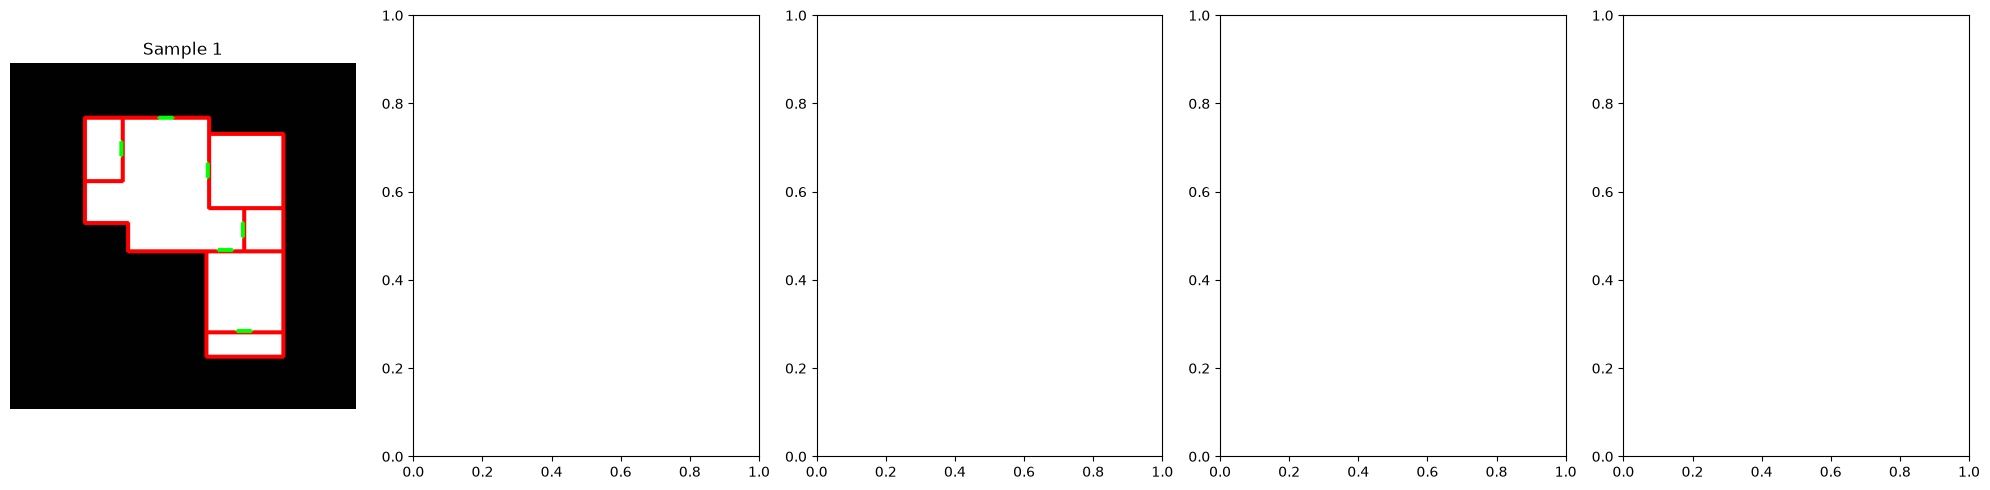

In [2]:

def viz_dataloaders(loader):
    fig, axes = plt.subplots(1, 5, figsize=(20, 5))
    for i, batch in enumerate(loader):
        image = batch[0] if isinstance(batch, (tuple, list)) else batch

        # Remove batch dimension
        image = image.squeeze(0)

        # Convert C,H,W -> H,W,C if necessary
        if image.ndim == 3 and image.shape[0] in (1, 3, 4):
            image = image.permute(1, 2, 0)

        # Convert grayscale to 2D
        if image.shape[-1] == 1:
            image = image.squeeze(-1)

        axes[i].imshow(image.cpu().numpy())
        axes[i].set_title(f"Sample {i + 1}")
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()   

train_loader = get_dataloader(num_samples=1, batch_size=1)

viz_dataloaders(train_loader)    

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..1.0].


tensor(-1.) tensor(1.)
tensor(0.) tensor(1.)


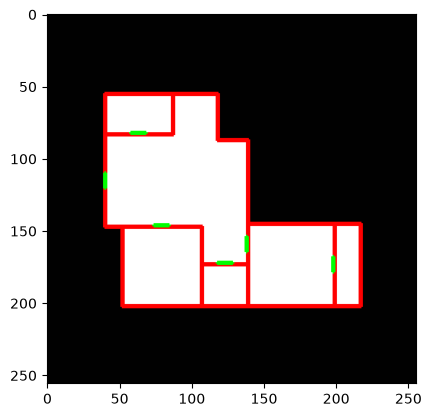

In [3]:
floorplan, outershell_mask, node_features, edge_features = next(iter(train_loader))
plt.imshow(floorplan.squeeze(0).permute(2,1,0))
print(min(floorplan.flatten()), max(floorplan.flatten()))
print(min(outershell_mask.flatten()), max(outershell_mask.flatten()))

In [4]:
train_losses = []
for epoch in range(epochs):
    model.train()
    encoder.train()
    total_loss = 0.0
    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch [{epoch + 1}/{epochs}]",
        leave=True
    )
    for floorplan, outershell_mask, node_features, edge_features in progress_bar:
        floorplan = floorplan.to(device)
        outershell_mask = outershell_mask.to(device)
        node_features = [x.to(device) for x in node_features]
        edge_features = [x.to(device) for x in edge_features]

        # TODO: Multiple batches
        condition = encoder(
            outershell_mask,
            node_features[0],
            edge_features[0]
        )

        condition = condition.to(device)
        loss = diffusion.loss(
            floorplan,
            condition
        )
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    avg_loss = total_loss / len(train_loader)
    train_losses.append(avg_loss)
    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {avg_loss:.6f}"
    )
    

Epoch [1/200]: 100%|██████████| 1/1 [00:01<00:00,  1.06s/it]


Epoch [1/200] Loss: 1.101332


Epoch [2/200]: 100%|██████████| 1/1 [00:00<00:00,  1.92it/s]


Epoch [2/200] Loss: 1.054362


Epoch [3/200]: 100%|██████████| 1/1 [00:00<00:00,  1.86it/s]


Epoch [3/200] Loss: 1.020141


... (390 outputs left out)

Epoch [199/200]: 100%|██████████| 1/1 [00:00<00:00,  1.76it/s]


Epoch [199/200] Loss: 0.145494


Epoch [200/200]: 100%|██████████| 1/1 [00:00<00:00,  1.90it/s]

Epoch [200/200] Loss: 0.238093


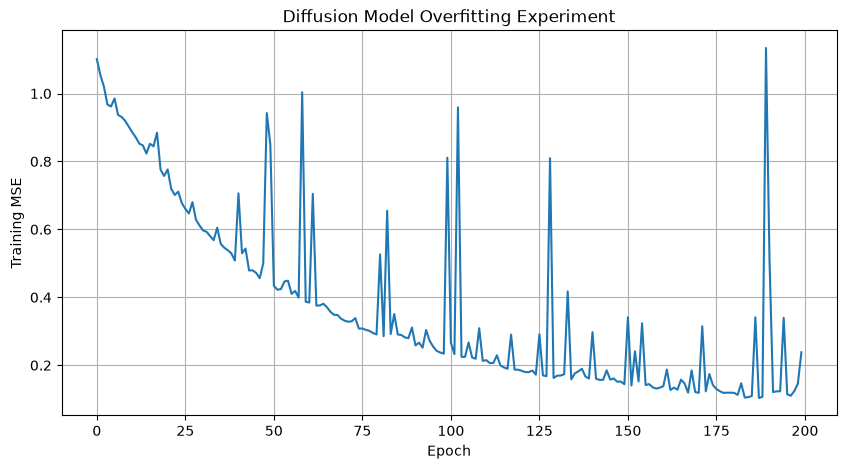

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(train_losses)

plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Diffusion Model Overfitting Experiment")

plt.grid()
plt.show()

cuda:0 torch.Size([1, 512, 8, 8])


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-363.60428..338.43643].


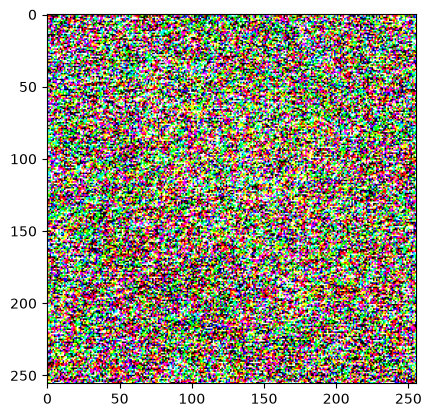

In [6]:

model.eval()
encoder.eval()

it = iter(train_loader)
for _ in range(len(train_loader)):
    floorplan, outershell_mask, node_features, edge_features = next(it)

    # Add batch dimension
    img = floorplan.unsqueeze(0).to(device)
    house_mask = outershell_mask.unsqueeze(0).to(device)
    with torch.no_grad():
        floorplan = floorplan.to(device)
        outershell_mask = outershell_mask.to(device)
        node_features = [x.to(device) for x in node_features]
        edge_features = [x.to(device) for x in edge_features]

        condition = encoder(
            outershell_mask,
            node_features[0],
            edge_features[0]
        )
        print(condition.device, condition.shape)

        generated_floorplan = diffusion.sample(
            condition,
            image_size=256,
            channels=3
        )
        plt.imshow(generated_floorplan.cpu().squeeze().permute(1,2,0))
        plt.show()